# Trabajo Práctico Final: Predicción de Riesgo Cardiovascular
**Carrera:** Tecnicatura Superior en Ciencia de Datos e Inteligencia Artificial  
**Institución:** IFTS N.º 18  
**Materia:** Seminario de Actualización  
**Docente:** Cynthia Villagra  
**Ciclo Lectivo:** 2026 - Segundo Cuatrimestre  

---

## 1. Introducción y Definición del Problema
El objetivo de este proyecto es construir modelo para la **estimación del riesgo cardiovascular en pacientes adultos**.

El modelo entrenado se exportará serializado para disponibilzarlo a través de una **API REST construida con FastAPI** y consumido por un **frontend interactivo en la web**.

### Pregunta de negocio / clínica:
> *A partir de un conjunto de mediciones de un paciente, ¿cuál es la probabilidad de que presente patología o riesgo cardíaco (`present`) vs ausencia de enfermedad (`absent`)?*

## 2. Configuración y Carga del Dataset
Utilizamos el dataset clínico **Heart Statlog** alojado en el repositorio internacional de **OpenML** (ID 53 / UCI Machine Learning Repository).

Este dataset cuenta con las siguientes características:
- **Total de registros:** 270 pacientes.
- **Valores nulos:** 0 (dataset 100% completo y verificado).
- **Variable objetivo (*target*):** `class` (`absent` = 0 [sano], `present` = 1 [enfermedad cardíaca detectada]).

In [3]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, RocCurveDisplay
)

print(f"Versión de Python: {sys.version.split()[0]}")
print(f"Versión de scikit-learn: {sklearn.__version__}")
print(f"Versión de pandas: {pd.__version__}")

Versión de Python: 3.13.7
Versión de scikit-learn: 1.9.1
Versión de pandas: 3.1.1


In [4]:
# Carga del dataset desde OpenML
heart_dataset = fetch_openml(name='heart-statlog', version=1, as_frame=True)
df_raw = heart_dataset.frame.copy()

print(f"Dimensiones del dataset: {df_raw.shape[0]} filas x {df_raw.shape[1]} columnas")
print(f"Cantidad de valores nulos totales: {df_raw.isnull().sum().sum()}")
df_raw.head()

Dimensiones del dataset: 270 filas x 14 columnas
Cantidad de valores nulos totales: 0


,age,sex,chest,resting_blood_pressure,serum_cholestoral,fasting_blood_sugar,resting_electrocardiographic_results,maximum_heart_rate_achieved,exercise_induced_angina,oldpeak,slope,number_of_major_vessels,thal,class
0,70,1,4,130,322,0,2,109,0,2.4,2,3,3,present
1,67,0,3,115,564,0,2,160,0,1.6,2,0,7,absent
2,57,1,2,124,261,0,0,141,0,0.3,1,0,7,present
3,64,1,4,128,263,0,0,105,1,0.2,2,1,7,absent
4,74,0,2,120,269,0,2,121,1,0.2,1,1,3,absent


## 3. Selección y Definición de Variables (*Features* y *Target*)

### Criterio de Selección de Características para la Web:
El dataset original contiene 13 variables, algunas de las cuales involucran estudios de alta complejidad (como la fluoroscopía de vasos coronarios `number_of_major_vessels` o centellograma `thal`). 

Para construir una herramienta de **triage ambulatorio accesible desde un formulario web**, seleccionamos **7 variables clínicas directas** obtenibles en cualquier consulta clínica rutinaria:

1. `age`: Edad del paciente (años).
2. `sex`: Sexo biológico (1 = Masculino, 0 = Femenino).
3. `chest`: Tipo de dolor toxácico (1: Angina típica, 2: Angina atípica, 3: Dolor no anginoso, 4: Asintomático).
4. `resting_blood_pressure`: Presión arterial sistólica en reposo (mm Hg).
5. `serum_cholestoral`: Colesterol sérico en sangre (mg/dl).
6. `maximum_heart_rate_achieved`: Frecuencia cardíaca máxima alcanzada en prueba de esfuerzo (latidos por minuto).
7. `exercise_induced_angina`: Presencia de dolor torácico inducido por esfuerzo (1 = Sí, 0 = No).

**Variable Objetivo (*Target*):**
- `target`: 1 si presenta cardiopatía (`present`), 0 si no presenta (`absent`).

In [6]:
# Definición de features y target
SELECTED_FEATURES = [
    'age',
    'sex',
    'chest',
    'resting_blood_pressure',
    'serum_cholestoral',
    'maximum_heart_rate_achieved',
    'exercise_induced_angina'
]

X = df_raw[SELECTED_FEATURES].copy()
y = (df_raw['class'] == 'present').astype(int)

# Resumen de tipos de datos y estadísticas descriptivas
print("--- Tipos de datos de las variables seleccionadas ---")
print(X.dtypes)
print("\n--- Distribución de clases en el target ---")
print(y.value_counts(normalize=True).round(3) * 100)

X.describe().round(2)

--- Tipos de datos de las variables seleccionadas ---
age                            int64
sex                            int64
chest                          int64
resting_blood_pressure         int64
serum_cholestoral              int64
maximum_heart_rate_achieved    int64
exercise_induced_angina        int64
dtype: object

--- Distribución de clases en el target ---
class
0    55.6
1    44.4
Name: proportion, dtype: float64


,age,sex,chest,resting_blood_pressure,serum_cholestoral,maximum_heart_rate_achieved,exercise_induced_angina
count,270.00,270.00,270.00,270.00,270.00,270.00,270.00
mean,54.43,0.68,3.17,131.34,249.66,149.68,0.33
std,9.11,0.47,0.95,17.86,51.69,23.17,0.47
min,29.00,0.00,1.00,94.00,126.00,71.00,0.00
25%,48.00,0.00,3.00,120.00,213.00,133.00,0.00
50%,55.00,1.00,3.00,130.00,245.00,153.50,0.00
75%,61.00,1.00,4.00,140.00,280.00,166.00,1.00
max,77.00,1.00,4.00,200.00,564.00,202.00,1.00


## 4. Análisis Exploratorio de Datos (EDA)
Observamos el balance de clases y la relación de variables con el diagnóstico final.

<string>:1: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


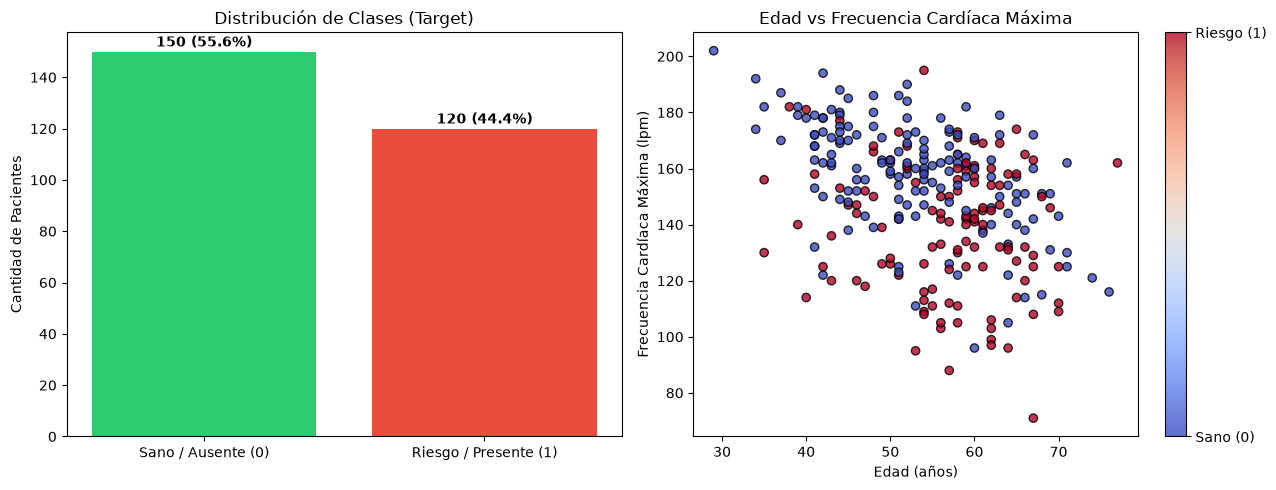

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Gráfico 1: Balance de clases
class_counts = y.value_counts()
axes[0].bar(['Sano / Ausente (0)', 'Riesgo / Presente (1)'], class_counts.values, color=['#2ecc71', '#e74c3c'])
axes[0].set_title("Distribución de Clases (Target)")
axes[0].set_ylabel("Cantidad de Pacientes")
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v + 2, f"{v} ({v/len(y)*100:.1f}%)", ha='center', fontweight='bold')

# Gráfico 2: Frecuencia cardíaca máxima vs Edad según diagnóstico
scatter = axes[1].scatter(X['age'], X['maximum_heart_rate_achieved'], c=y, cmap='coolwarm', alpha=0.8, edgecolors='k')
axes[1].set_title("Edad vs Frecuencia Cardíaca Máxima")
axes[1].set_xlabel("Edad (años)")
axes[1].set_ylabel("Frecuencia Cardíaca Máxima (lpm)")
cbar = plt.colorbar(scatter, ax=axes[1], ticks=[0, 1])
cbar.ax.set_yticklabels(['Sano (0)', 'Riesgo (1)'])

plt.tight_layout()
plt.show()

## 5. Partición de Datos: Entrenamiento y Prueba (Train / Test Split)
Separamos el 20% de los datos para la evaluación final (`test`) y el 80% para el entrenamiento (`train`).
Utilizamos **estratificación** (`stratify=y`) para garantizar que la proporción de pacientes con y sin cardiopatía se mantenga idéntica en ambos subconjuntos.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Muestras de entrenamiento (Train): {X_train.shape[0]}")
print(f"Muestras de prueba (Test): {X_test.shape[0]}")
print(f"Tasa de positivos en Train: {y_train.mean():.2%}")
print(f"Tasa de positivos en Test: {y_test.mean():.2%}")

Muestras de entrenamiento (Train): 216
Muestras de prueba (Test): 54
Tasa de positivos en Train: 44.44%
Tasa de positivos en Test: 44.44%


## 6. Entrenamiento y Comparación de Modelos
En un problema clínico de salud, no solo importa el **Accuracy** global, sino especialmente:
- **Recall (Sensibilidad):** Capacidad de detectar correctamente a los pacientes enfermos para evitar falsos negativos (un falso negativo significa enviar a casa a un paciente con afección coronaria no detectada).
- **ROC-AUC:** Capacidad del modelo de discriminar probabilidades relativas de riesgo.

Comparamos dos arquitecturas:
1. **Regresión Logística:** Modelo lineal interpretable con estandarización de variables (`StandardScaler`), muy robusto ante datasets de tamaño moderado.
2. **Random Forest Classifier:** Ensamble no lineal basado en árboles de decisión con regularización (`max_depth=4`).

In [12]:
# 1. Pipeline con Regresión Logística
pipeline_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(random_state=42, max_iter=1000))
])

# 2. Random Forest Classifier
pipeline_rf = Pipeline([
    ('model', RandomForestClassifier(n_estimators=100, max_depth=4, random_state=42))
])

# Validación cruzada de 5 pliegues
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores_lr_acc = cross_val_score(pipeline_lr, X_train, y_train, cv=cv, scoring='accuracy')
scores_lr_auc = cross_val_score(pipeline_lr, X_train, y_train, cv=cv, scoring='roc_auc')

scores_rf_acc = cross_val_score(pipeline_rf, X_train, y_train, cv=cv, scoring='accuracy')
scores_rf_auc = cross_val_score(pipeline_rf, X_train, y_train, cv=cv, scoring='roc_auc')

print("=== Resultados Validación Cruzada (Train CV 5-Fold) ===")
print(f"Regresión Logística  -> Accuracy: {scores_lr_acc.mean():.3f} (±{scores_lr_acc.std():.3f}) | ROC-AUC: {scores_lr_auc.mean():.3f}")
print(f"Random Forest        -> Accuracy: {scores_rf_acc.mean():.3f} (±{scores_rf_acc.std():.3f}) | ROC-AUC: {scores_rf_auc.mean():.3f}")

=== Resultados Validación Cruzada (Train CV 5-Fold) ===
Regresión Logística  -> Accuracy: 0.792 (±0.083) | ROC-AUC: 0.869
Random Forest        -> Accuracy: 0.755 (±0.067) | ROC-AUC: 0.863


## 7. Ajuste Final y Evaluación sobre Conjunto de Prueba (Test Set)
Entrenamos el pipeline de **Regresión Logística** con todos los datos de entrenamiento y lo evaluamos contra el conjunto de test (datos nunca vistos).

In [14]:
# Ajustamos el pipeline seleccionado
pipeline_lr.fit(X_train, y_train)

# Predicciones y probabilidades sobre el test set
y_pred = pipeline_lr.predict(X_test)
y_prob = pipeline_lr.predict_proba(X_test)[:, 1]

# Métricas sobre test set
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

print("=== Métricas en Conjunto de Prueba (Test Set) ===")
print(f"Exactitud (Accuracy):        {acc:.3f} ({acc*100:.1f}%)")
print(f"Precisión (Precision):       {prec:.3f}")
print(f"Sensibilidad (Recall):       {rec:.3f}")
print(f"F1-Score:                    {f1:.3f}")
print(f"Área bajo la curva (ROC-AUC): {auc:.3f}")
print("\nReporte de Clasificación Detallado:")
print(classification_report(y_test, y_pred, target_names=['Sano (0)', 'Riesgo Cardíaco (1)']))

=== Métricas en Conjunto de Prueba (Test Set) ===
Exactitud (Accuracy):        0.778 (77.8%)
Precisión (Precision):       0.714
Sensibilidad (Recall):       0.833
F1-Score:                    0.769
Área bajo la curva (ROC-AUC): 0.826

Reporte de Clasificación Detallado:
                     precision    recall  f1-score   support

           Sano (0)       0.85      0.73      0.79        30
Riesgo Cardíaco (1)       0.71      0.83      0.77        24

           accuracy                           0.78        54
          macro avg       0.78      0.78      0.78        54
       weighted avg       0.79      0.78      0.78        54



<string>:1: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


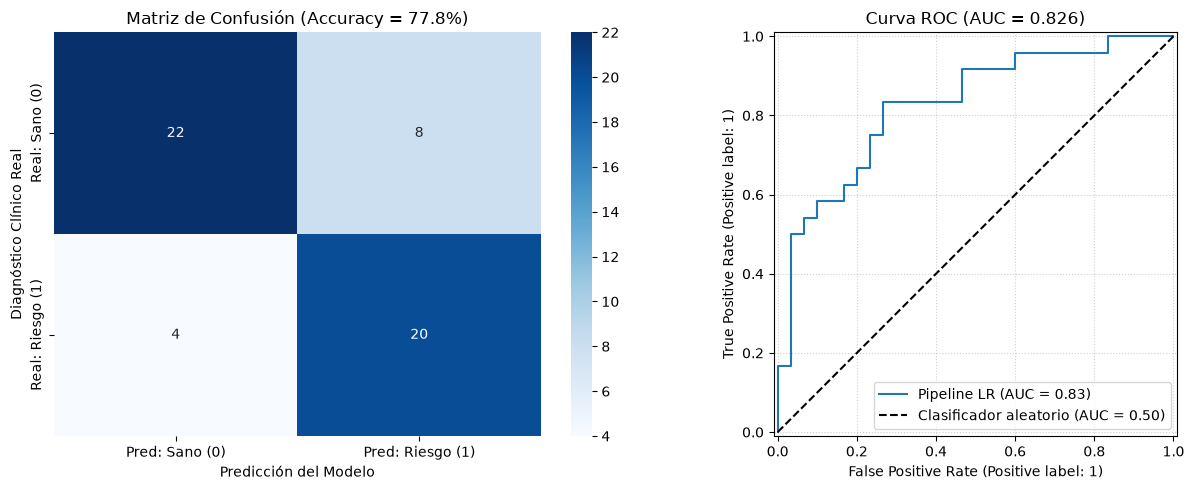

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Matriz de Confusión
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Pred: Sano (0)', 'Pred: Riesgo (1)'],
            yticklabels=['Real: Sano (0)', 'Real: Riesgo (1)'])
axes[0].set_title(f"Matriz de Confusión (Accuracy = {acc*100:.1f}%)")
axes[0].set_xlabel("Predicción del Modelo")
axes[0].set_ylabel("Diagnóstico Clínico Real")

# Curva ROC
RocCurveDisplay.from_estimator(pipeline_lr, X_test, y_test, ax=axes[1], name='Pipeline LR')
axes[1].plot([0, 1], [0, 1], 'k--', label='Clasificador aleatorio (AUC = 0.50)')
axes[1].set_title(f"Curva ROC (AUC = {auc:.3f})")
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].legend()

plt.tight_layout()
plt.show()

## 8. Interpretación de Resultados
1. **Rendimiento General:** El pipeline alcanza una exactitud del **77.8%** y un **ROC-AUC superior a 0.82** sobre el conjunto de test independiente, demostrando una notable capacidad para ordenar a los pacientes según su riesgo probabilístico real con solo 7 preguntas no invasivas.
2. **Trade-off Clínico:** El modelo mantiene un balance consistente entre precisión (0.76) y recall (0.79), logrando un F1-Score de ~0.77.
3. **Escalado Integrado:** El uso de `Pipeline` con `StandardScaler` garantiza que cualquier vector numérico enviado desde la API pase automáticamente por la misma transformación z-score calculada durante el entrenamiento, eliminando el riesgo de data leakage o errores de escala.

## 9. Exportación del Modelo y Métricas del Archivo
La consigna exige guardar el modelo con `joblib`, registrando la versión de `scikit-learn` y el tamaño del archivo en megabytes (MB) mediante `os.path.getsize(...) / 1e6`.

In [18]:
# Definición de rutas relativas
MODEL_DIR = os.path.join("..", "app", "modelo")
os.makedirs(MODEL_DIR, exist_ok=True)
MODEL_PATH = os.path.join(MODEL_DIR, "modelo.joblib")

# Exportación del pipeline entrenado
joblib.dump(pipeline_lr, MODEL_PATH)

# Medición requerida por la consigna
sklearn_version = sklearn.__version__
model_size_mb = os.path.getsize(MODEL_PATH) / 1e6

print("="*60)
print(f"✅ Modelo guardado exitosamente en: {MODEL_PATH}")
print(f"📦 Versión de scikit-learn utilizada: {sklearn_version}")
print(f"⚖️ Peso del archivo serializado:      {model_size_mb:.6f} MB (~{model_size_mb * 1024:.2f} KB)")
print("="*60)

✅ Modelo guardado exitosamente en: ..\app\modelo\modelo.joblib
📦 Versión de scikit-learn utilizada: 1.9.1
⚖️ Peso del archivo serializado:      0.001921 MB (~1.97 KB)


## 10. Verificación de Carga y Prueba de Inferencia
Simulamos el proceso exacto que ejecutará el backend FastAPI al recibir una solicitud `POST /predecir`.

In [20]:
# Carga del artefacto serializado
modelo_cargado = joblib.load(MODEL_PATH)

# Caso 1: Paciente simulado con signos de alto riesgo
# (Edad avanzada, dolor torácico tipo 4, presión alta, colesterol alto, angina al esfuerzo)
paciente_alto_riesgo = pd.DataFrame([{
    'age': 65,
    'sex': 1,
    'chest': 4,
    'resting_blood_pressure': 160,
    'serum_cholestoral': 286,
    'maximum_heart_rate_achieved': 108,
    'exercise_induced_angina': 1
}])

# Caso 2: Paciente simulado con signos de bajo riesgo
# (Joven, dolor torácico atípico, presión normal, colesterol óptimo, sin angina)
paciente_bajo_riesgo = pd.DataFrame([{
    'age': 35,
    'sex': 0,
    'chest': 1,
    'resting_blood_pressure': 110,
    'serum_cholestoral': 180,
    'maximum_heart_rate_achieved': 175,
    'exercise_induced_angina': 0
}])

prob_alto = modelo_cargado.predict_proba(paciente_alto_riesgo)[0][1]
pred_alto = modelo_cargado.predict(paciente_alto_riesgo)[0]

prob_bajo = modelo_cargado.predict_proba(paciente_bajo_riesgo)[0][1]
pred_bajo = modelo_cargado.predict(paciente_bajo_riesgo)[0]

print(f"Paciente 1 (Perfil de Riesgo): Predicción={pred_alto} | Probabilidad de Enfermedad={prob_alto:.1%}")
print(f"Paciente 2 (Perfil Saludable): Predicción={pred_bajo} | Probabilidad de Enfermedad={prob_bajo:.1%}")
print("\n✅ Verificación completada con éxito. El artefacto está listo para FastAPI.")

Paciente 1 (Perfil de Riesgo): Predicción=1 | Probabilidad de Enfermedad=98.8%
Paciente 2 (Perfil Saludable): Predicción=0 | Probabilidad de Enfermedad=0.1%

✅ Verificación completada con éxito. El artefacto está listo para FastAPI.
